# LAB 04: Tiền xử lý dữ liệu và Feature Selection
**Dataset:** Ames House Price (Kaggle) · **Mô hình:** SVM (SVR), Random Forest, XGBoost · **Biến mục tiêu:** `log1p(SalePrice)`

Thiết kế chung của notebook:
- Mọi bước có học tham số (điền thiếu, mã hóa, biến đổi, chuẩn hóa, chọn đặc trưng) nằm **trong `Pipeline`**, nên mỗi fold của cross-validation tự `fit` trên tập train của fold đó, không rò rỉ dữ liệu.
- Chỉ **một đường xử lý** duy nhất (pipeline) được dùng cho cả baseline lẫn Feature Selection, để các kết quả so sánh được với nhau.

## 0. Tóm tắt EDA (Lab 03)
- **Dữ liệu:** train 1.460 × 81 (79 biến giải thích, `Id`, `SalePrice`), test 1.459 × 80.
- **Biến mục tiêu:** lệch phải (skew 1,88), sau `log1p` còn 0,12 → huấn luyện trên `log1p(SalePrice)`, đổi ngược bằng `expm1`.
- **Kiểu biến:** 33 numeric, 20 ordinal, 26 nominal (gồm `MSSubClass`, `MoSold`, `YrSold` vốn lưu dạng số).
- **Đa cộng tuyến:** `GarageCars–GarageArea` (0,88), `GrLivArea–TotRmsAbvGrd` (0,83), `TotalBsmtSF–1stFlrSF` (0,82). Theo VIF, bỏ `GarageArea` và `TotRmsAbvGrd`.
- **Thiếu dữ liệu:** phần lớn NA nghĩa là "không có tiện ích" (Pool, Alley, Fence, Garage, Basement…); thiếu thật gồm `LotFrontage`, `MasVnrArea`, `Electrical`.
- **Ngoại lệ:** loại Id **524, 1299**; giữ 692, 1183. Biến lệch (`LotArea`, `LotFrontage`…) xử lý bằng biến đổi, không xóa dòng.

## 1. Tiền xử lý dữ liệu
### 1.1 Tổng quan dữ liệu và biến mục tiêu

In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.model_selection import KFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, PowerTransformer, StandardScaler
from sklearn.svm import SVR
from xgboost import XGBRegressor

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

In [2]:
# Trong file gốc, "NA" nghĩa là thiếu. Chuỗi "None" (vd MasVnrType = không ốp tường) là giá trị thật,
# nên chỉ coi "NA" và ô trống là NaN, tránh việc pandas tự đổi "None" thành NaN.
def load_csv(path):
    return pd.read_csv(path, keep_default_na=False, na_values=["NA", ""])

train = load_csv("data/train.csv")
test = load_csv("data/test.csv")
print("Train:", train.shape, "| Test:", test.shape)
print("MasVnrType:", train["MasVnrType"].value_counts(dropna=False).to_dict())

Train: (1460, 81) | Test: (1459, 80)
MasVnrType: {'None': 864, 'BrkFace': 445, 'Stone': 128, 'BrkCmn': 15, nan: 8}


,count,mean,std,min,25%,50%,75%,max
SalePrice,1460.0,180921.19589,79442.502883,34900.0,129975.0,163000.0,214000.0,755000.0


Skew SalePrice: 1.883 -> sau log1p: 0.121


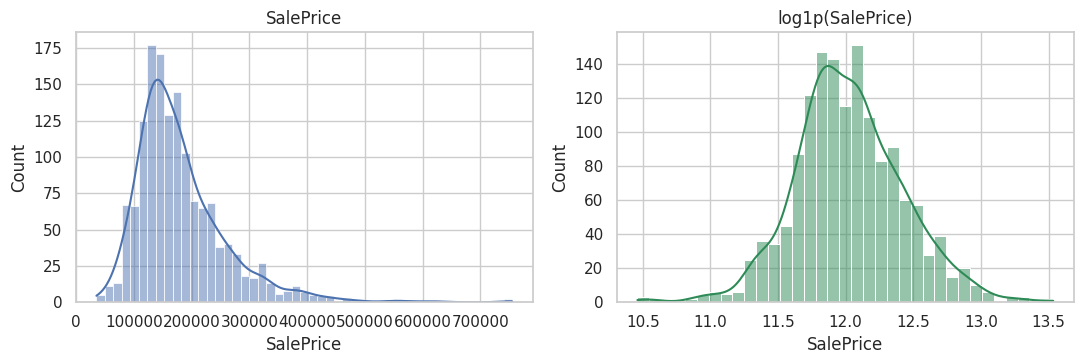

In [3]:
display(train["SalePrice"].describe().to_frame().T)
print(f"Skew SalePrice: {train['SalePrice'].skew():.3f} -> sau log1p: {np.log1p(train['SalePrice']).skew():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
sns.histplot(train["SalePrice"], kde=True, ax=axes[0]).set(title="SalePrice")
sns.histplot(np.log1p(train["SalePrice"]), kde=True, ax=axes[1], color="seagreen").set(title="log1p(SalePrice)")
plt.tight_layout()
plt.show()

In [4]:
# Cross-validation 5 fold và metric: RMSE trên log1p(SalePrice), R2
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"RMSE": "neg_root_mean_squared_error", "R2": "r2"}

### 1.2 Xử lý outlier

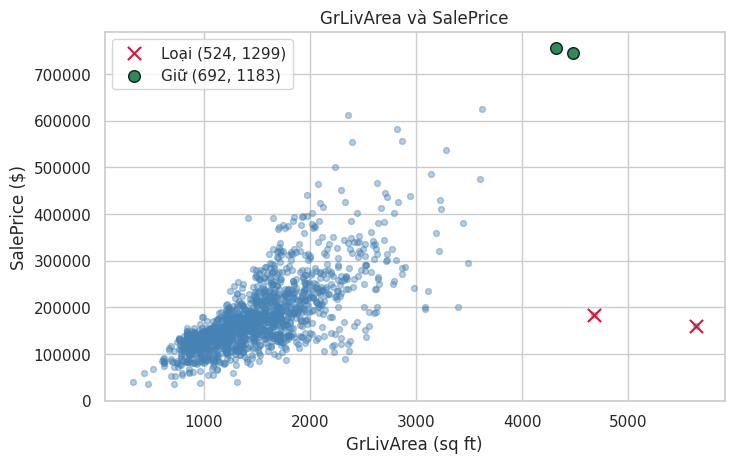

Số dòng: 1460 -> 1458


,Slope ($/sqft),Pearson r
Trước khi loại,107.13,0.709
Sau khi loại,115.04,0.735


In [5]:
OUTLIER_IDS = [524, 1299]   # GrLivArea rất lớn nhưng giá thấp (bán dạng Partial) -> loại
KEPT_IDS = [692, 1183]      # diện tích rất lớn và giá cao -> hợp lý, giữ lại

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.scatter(train["GrLivArea"], train["SalePrice"], s=18, alpha=0.4, color="steelblue")
for ids, style in [(OUTLIER_IDS, dict(color="crimson", marker="x", s=90, label="Loại (524, 1299)")),
                   (KEPT_IDS, dict(color="seagreen", marker="o", s=70, edgecolor="k", label="Giữ (692, 1183)"))]:
    rows = train[train["Id"].isin(ids)]
    ax.scatter(rows["GrLivArea"], rows["SalePrice"], **style)
ax.set(title="GrLivArea và SalePrice", xlabel="GrLivArea (sq ft)", ylabel="SalePrice ($)")
ax.legend()
plt.show()

out = train[train["Id"].isin(OUTLIER_IDS)]
assert (out["GrLivArea"] > 4000).all() and (out["SalePrice"] < 300000).all()

# Tập dùng để mô hình hóa: bỏ đúng hai ngoại lệ (quyết định cố định, không học từ dữ liệu)
train_model = train[~train["Id"].isin(OUTLIER_IDS)].reset_index(drop=True)
y = np.log1p(train_model["SalePrice"])
print(f"Số dòng: {len(train)} -> {len(train_model)}")

def slope_r(df):
    return np.polyfit(df["GrLivArea"], df["SalePrice"], 1)[0], df["GrLivArea"].corr(df["SalePrice"])
cmp_df = pd.DataFrame([slope_r(train), slope_r(train_model)], columns=["Slope ($/sqft)", "Pearson r"],
                      index=["Trước khi loại", "Sau khi loại"])
display(cmp_df.round(3))

In [6]:
# Cờ IQR chỉ để báo cáo: các biến lệch này được xử lý bằng biến đổi ở mục 1.5, không xóa dòng
rows = []
for col in ["LotArea", "MasVnrArea", "LotFrontage", "OpenPorchSF"]:
    v = train_model[col].dropna()
    q1, q3 = v.quantile([0.25, 0.75])
    flagged = ((v < q1 - 1.5 * (q3 - q1)) | (v > q3 + 1.5 * (q3 - q1))).sum()
    rows.append({"Feature": col, "IQR flagged": int(flagged), "Non-null": len(v), "Skew": round(v.skew(), 2)})
display(pd.DataFrame(rows).set_index("Feature"))

,IQR flagged,Non-null,Skew
Feature,,,
LotArea,66,1458,12.57
MasVnrArea,96,1450,2.69
LotFrontage,86,1199,1.54
OpenPorchSF,75,1458,2.34


### 1.3 Kiểm tra dữ liệu thiếu

In [7]:
# NA ở các cột này nghĩa là "không có tiện ích" (không phải thiếu ngẫu nhiên)
NA_ABSENT = ["PoolQC", "MiscFeature", "Alley", "Fence", "FireplaceQu", "GarageType", "GarageFinish",
             "GarageQual", "GarageCond", "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2"]

miss = train_model.isna().sum()
missing_summary = pd.DataFrame({"Số dòng thiếu": miss, "Tỷ lệ (%)": (miss / len(train_model) * 100).round(2)})
missing_summary = missing_summary[missing_summary["Số dòng thiếu"] > 0].sort_values("Số dòng thiếu", ascending=False)
missing_summary["Loại"] = np.where(missing_summary.index.isin(NA_ABSENT), "NA = không có tiện ích", "khuyết thật")
display(missing_summary)

# MasVnrType chỉ còn 8 dòng thiếu thật; kiểm tra chúng trùng với MasVnrArea thiếu
display(train_model.loc[train_model["MasVnrType"].isna(), ["Id", "MasVnrType", "MasVnrArea"]])
print("Nhóm Garage: GarageType NA =", train_model["GarageType"].isna().sum(),
      "| cùng dòng GarageYrBlt NA =", (train_model["GarageType"].isna() & train_model["GarageYrBlt"].isna()).sum(),
      "| GarageArea = 0 =", (train_model.loc[train_model["GarageType"].isna(), "GarageArea"] == 0).sum())

,Số dòng thiếu,Tỷ lệ (%),Loại
PoolQC,1452,99.59,NA = không có tiện ích
MiscFeature,1404,96.30,NA = không có tiện ích
Alley,1367,93.76,NA = không có tiện ích
Fence,1177,80.73,NA = không có tiện ích
FireplaceQu,690,47.33,NA = không có tiện ích
LotFrontage,259,17.76,khuyết thật
GarageCond,81,5.56,NA = không có tiện ích
GarageType,81,5.56,NA = không có tiện ích
GarageYrBlt,81,5.56,khuyết thật
GarageFinish,81,5.56,NA = không có tiện ích


,Id,MasVnrType,MasVnrArea
234,235,NaN,NaN
528,530,NaN,NaN
649,651,NaN,NaN
935,937,NaN,NaN
972,974,NaN,NaN
976,978,NaN,NaN
1242,1244,NaN,NaN
1277,1279,NaN,NaN


Nhóm Garage: GarageType NA = 81 | cùng dòng GarageYrBlt NA = 81 | GarageArea = 0 = 81


**Quyết định điền (thực hiện trong pipeline ở mục 1.5, học tham số theo từng fold):**

| Nhóm | Cột | Cách điền |
|---|---|---|
| NA = không có tiện ích (chữ) | `PoolQC`, `Fence`, `FireplaceQu`, `Garage*`, `Bsmt*`, `Alley`, `MiscFeature` | `"None"` |
| `MasVnrType` (8 dòng) | trùng với `MasVnrArea` thiếu → không có ốp tường | `"None"` (và `MasVnrArea` = median = 0) |
| Khuyết thật (số) | `LotFrontage`, `MasVnrArea`, `GarageYrBlt` | median |
| Khuyết thật (chữ) | `Electrical` và các cột còn lại | mode |

`GarageYrBlt` điền **median** (không điền 0) kèm cờ `HasGarage`: điền 0 sẽ tạo điểm cực đoan (năm 0) làm méo thang đo của SVM, còn thông tin "không có gara" đã nằm trong `HasGarage`.

### 1.4 Encoding

In [8]:
QUAL = ["None", "Po", "Fa", "TA", "Gd", "Ex"]
FIN = ["None", "Unf", "LwQ", "Rec", "BLQ", "ALQ", "GLQ"]
# 20 biến ordinal và thứ tự các mức (thấp -> cao)
ORD = {
    "ExterQual": QUAL, "KitchenQual": QUAL, "BsmtQual": QUAL, "HeatingQC": QUAL, "GarageQual": QUAL,
    "PoolQC": QUAL, "ExterCond": QUAL, "BsmtCond": QUAL, "GarageCond": QUAL, "FireplaceQu": QUAL,
    "BsmtExposure": ["None", "No", "Mn", "Av", "Gd"], "BsmtFinType1": FIN, "BsmtFinType2": FIN,
    "GarageFinish": ["None", "Unf", "RFn", "Fin"],
    "Functional": ["Sal", "Sev", "Maj2", "Maj1", "Mod", "Min2", "Min1", "Typ"],
    "LotShape": ["IR3", "IR2", "IR1", "Reg"], "LandSlope": ["Sev", "Mod", "Gtl"],
    "PavedDrive": ["N", "P", "Y"], "CentralAir": ["N", "Y"],
    "Fence": ["None", "MnWw", "GdWo", "MnPrv", "GdPrv"],
}
CODE_COLS = ["MSSubClass", "MoSold", "YrSold"]   # số nguyên nhưng là mã danh mục

def prepare(df):
    # bỏ Id/SalePrice, thêm cờ HasGarage (tính theo từng dòng nên không gây rò rỉ), ép biến mã sang chuỗi
    X = df.drop(columns=[c for c in ["Id", "SalePrice"] if c in df.columns]).copy()
    X["HasGarage"] = (X["GarageArea"].fillna(0) > 0).astype(int)
    for c in CODE_COLS:
        X[c] = X[c].astype(str)
    return X

X, X_test = prepare(train_model), prepare(test)

ORDINAL = list(ORD)
NUMERIC = [c for c in X.columns if pd.api.types.is_numeric_dtype(X[c])]
NOMINAL = [c for c in X.columns if c not in NUMERIC and c not in ORDINAL]
print(f"Numeric: {len(NUMERIC)} (gồm HasGarage) | Ordinal: {len(ORDINAL)} | Nominal: {len(NOMINAL)}")
assert (len(NUMERIC), len(ORDINAL), len(NOMINAL)) == (34, 20, 26)
assert list(X.columns) == list(X_test.columns) and len(X) == len(y)
print("Nominal nhiều mức nhất:", X[NOMINAL].nunique().sort_values(ascending=False).head(4).to_dict())

Numeric: 34 (gồm HasGarage) | Ordinal: 20 | Nominal: 26
Nominal nhiều mức nhất: {'Neighborhood': 25, 'Exterior2nd': 16, 'Exterior1st': 15, 'MSSubClass': 15}


**Cách mã hóa:** ordinal → `OrdinalEncoder` theo thứ tự cho trước (mức lạ → -1); nominal → One-Hot (`handle_unknown="ignore"`). Cả `Neighborhood`, `Exterior1st/2nd` cũng dùng One-Hot thay vì Target Encoding để tránh rò rỉ nhãn.

### 1.5 Biến đổi và chuẩn hóa (cho SVM)

In [9]:
# Biến số lệch (|skew| > 0.75) và liên tục -> Yeo-Johnson.
# Loại các biến gần như toàn số 0 (MiscVal, PoolArea, 3SsnPorch...) và biến đếm ít giá trị: biến đổi không giảm lệch của chúng.
skew = X[NUMERIC].skew()
SKEWED = [c for c in NUMERIC
          if abs(skew[c]) > 0.75 and X[c].nunique() > 10 and (X[c] == 0).mean() < 0.9]
display(skew[SKEWED].round(2).to_frame("Skew").T)

ORD_NONE = ["PoolQC", "GarageQual", "GarageCond", "FireplaceQu", "BsmtQual", "BsmtCond",
            "BsmtExposure", "BsmtFinType1", "BsmtFinType2", "GarageFinish", "Fence"]   # NA = không có
NOM_NONE = ["Alley", "GarageType", "MiscFeature", "MasVnrType"]

def build_preprocessor(scale, exclude=()):
    # scale=True chỉ dùng cho SVM; exclude: các cột bị loại ngay từ đầu (dùng cho kỹ thuật lọc theo VIF)
    keep = lambda cols: [c for c in cols if c not in exclude]
    scaler = [("scaler", StandardScaler())] if scale else []
    none_imp = lambda: SimpleImputer(strategy="constant", fill_value="None")
    mode_imp = lambda: SimpleImputer(strategy="most_frequent")

    def ordinal(cols, imputer):
        enc = OrdinalEncoder(categories=[ORD[c] for c in cols], handle_unknown="use_encoded_value", unknown_value=-1)
        return Pipeline([("imp", imputer), ("enc", enc)] + scaler)

    def nominal(imputer):
        return Pipeline([("imp", imputer), ("enc", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])

    num_skew = keep(SKEWED)
    num_rest = keep([c for c in NUMERIC if c not in SKEWED])
    ord_none, ord_mode = keep(ORD_NONE), keep([c for c in ORDINAL if c not in ORD_NONE])
    nom_none, nom_mode = keep(NOM_NONE), keep([c for c in NOMINAL if c not in NOM_NONE])

    parts = [
        ("num_skew", Pipeline([("imp", SimpleImputer(strategy="median")),
                               ("yj", PowerTransformer(method="yeo-johnson", standardize=False))] + scaler), num_skew),
        ("num", Pipeline([("imp", SimpleImputer(strategy="median"))] + scaler), num_rest),
        ("ord_none", ordinal(ord_none, none_imp()), ord_none),
        ("ord_mode", ordinal(ord_mode, mode_imp()), ord_mode),
        ("nom_none", nominal(none_imp()), nom_none),
        ("nom_mode", nominal(mode_imp()), nom_mode),
    ]
    return ColumnTransformer([p for p in parts if p[2]], verbose_feature_names_out=False)

,LotFrontage,LotArea,MasVnrArea,BsmtFinSF1,BsmtFinSF2,BsmtUnfSF,1stFlrSF,2ndFlrSF,GrLivArea,WoodDeckSF,OpenPorchSF,EnclosedPorch
Skew,1.54,12.57,2.69,0.76,4.25,0.92,0.89,0.81,1.01,1.55,2.34,3.09


In [10]:
# Kiểm tra nhanh: fit trên train, áp dụng cho test (không NaN, cùng số cột)
pre_check = build_preprocessor(scale=True)
Z = pre_check.fit_transform(X)
Z_test = pre_check.transform(X_test)
print(f"Sau tiền xử lý: train {Z.shape}, test {Z_test.shape} | NaN: {np.isnan(Z).sum()} / {np.isnan(Z_test).sum()}")
assert Z.shape[1] == Z_test.shape[1] and not np.isnan(Z).any() and not np.isnan(Z_test).any()

Sau tiền xử lý: train (1458, 254), test (1459, 254) | NaN: 0 / 0


In [11]:
# Ba mô hình baseline; chỉ SVM dùng bộ tiền xử lý có scaler
MODELS = ["SVM", "Random Forest", "XGBoost"]

def make_model(name):
    if name == "SVM":
        return SVR(kernel="rbf", C=10.0, epsilon=0.02)
    if name == "Random Forest":
        return RandomForestRegressor(n_estimators=150, random_state=RANDOM_STATE, n_jobs=-1)
    return XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=3, subsample=0.8,
                        colsample_bytree=0.8, random_state=RANDOM_STATE, n_jobs=-1)

baseline = {}
for name in MODELS:
    pipe = Pipeline([("pre", build_preprocessor(scale=(name == "SVM"))), ("model", make_model(name))])
    r = cross_validate(pipe, X, y, cv=cv, scoring=scoring, error_score="raise")
    baseline[name] = {"RMSE mean": -r["test_RMSE"].mean(), "RMSE std": r["test_RMSE"].std(),
                      "R2 mean": r["test_R2"].mean(), "R2 std": r["test_R2"].std()}
display(pd.DataFrame(baseline).T.round(4))

,RMSE mean,RMSE std,R2 mean,R2 std
SVM,0.1388,0.0127,0.8780,0.0223
Random Forest,0.1375,0.0089,0.8803,0.0190
XGBoost,0.1159,0.0082,0.9151,0.0126


## 2. Feature Selection
**Mục đích:** đánh giá hiệu suất của các kỹ thuật chọn đặc trưng khi kết hợp với SVM, Random Forest và XGBoost.

**Thiết kế thí nghiệm**
- Bộ chọn đặc trưng nằm **giữa** `preprocessor` và `model` trong pipeline, nên mỗi fold tự chọn lại đặc trưng trên tập train của fold.
- Việc chọn thực hiện trên **cột sau mã hóa** (từng cột One-Hot), nên một biến gốc như `Neighborhood` có thể được giữ một phần.
- Cùng mô hình, cùng siêu tham số và cùng 5-fold CV cho mọi kỹ thuật; thay đổi duy nhất là cách chọn đặc trưng. Siêu tham số là cấu hình baseline cố định (không tinh chỉnh riêng cho từng kỹ thuật); `epsilon` của SVR được chọn sau khi thử nhanh 0,1 / 0,05 / 0,02 trên baseline.
- Số cột One-Hot hơi khác nhau giữa các fold (nhãn hiếm chỉ xuất hiện ở fold khác), nên số đặc trưng baseline là ≈ 250 chứ không đúng 254.
- Đo: RMSE trên log-price, R², số đặc trưng còn lại (trung bình các fold) và thời gian `fit`.

| Nhóm | Kỹ thuật | Số đặc trưng |
|---|---|---|
| Baseline | Tất cả đặc trưng | ≈ 250 (tùy fold) |
| Filter | Loại `GarageArea`, `TotRmsAbvGrd` theo VIF (từ EDA) | ≈ 248 |
| Filter | `SelectKBest` với `f_regression` | k = 20, 40, 80 |
| Filter | `SelectKBest` với Mutual Information | k = 20, 40, 80 |
| Embedded | Importance của Random Forest | k = 20, 40, 80 |
| Embedded | Lasso (`SelectFromModel`), α = 0,002 và 0,01 | do thuật toán quyết định |
| Wrapper | RFE với Random Forest | k = 20, 40, 80 |

In [12]:
from sklearn.feature_selection import RFE, SelectFromModel, SelectKBest, f_regression, mutual_info_regression
from sklearn.linear_model import Lasso

K_VALUES = [20, 40, 80]
VIF_DROP = ["GarageArea", "TotRmsAbvGrd"]

def small_forest(n):
    return RandomForestRegressor(n_estimators=n, random_state=RANDOM_STATE, n_jobs=-1)

def lasso_selector(alpha):
    # Lasso cần đặc trưng cùng thang đo nên có StandardScaler riêng (chỉ dùng để chọn, không đổi dữ liệu đưa vào mô hình)
    est = Pipeline([("sc", StandardScaler()), ("lasso", Lasso(alpha=alpha, max_iter=20000))])
    return SelectFromModel(est, importance_getter="named_steps.lasso.coef_")

techniques = [
    dict(name="Baseline (tất cả)", family="Baseline", k=None, exclude=(), make=lambda: "passthrough"),
    dict(name="VIF (EDA)", family="Filter-VIF", k=None, exclude=tuple(VIF_DROP), make=lambda: "passthrough"),
]
for k in K_VALUES:
    techniques += [
        dict(name=f"f_regression (k={k})", family="Filter-f_regression", k=k, exclude=(),
             make=lambda k=k: SelectKBest(f_regression, k=k)),
        dict(name=f"Mutual Info (k={k})", family="Filter-MI", k=k, exclude=(),
             make=lambda k=k: SelectKBest(lambda a, b: mutual_info_regression(a, b, random_state=RANDOM_STATE), k=k)),
        dict(name=f"RF importance (k={k})", family="Embedded-RF", k=k, exclude=(),
             make=lambda k=k: SelectFromModel(small_forest(100), max_features=k, threshold=-np.inf)),
        dict(name=f"RFE-RF (k={k})", family="Wrapper-RFE", k=k, exclude=(),
             make=lambda k=k: RFE(small_forest(40), n_features_to_select=k, step=0.2)),
    ]
for alpha in [0.002, 0.01]:
    techniques.append(dict(name=f"Lasso (alpha={alpha})", family="Embedded-Lasso", k=None, exclude=(),
                           make=lambda alpha=alpha: lasso_selector(alpha)))
print(len(techniques), "cấu hình ×", len(MODELS), "mô hình ×", cv.get_n_splits(), "fold")

16 cấu hình × 3 mô hình × 5 fold


In [13]:
rows = []
for tech in techniques:
    for name in MODELS:
        pipe = Pipeline([
            ("pre", build_preprocessor(scale=(name == "SVM"), exclude=tech["exclude"])),
            ("fs", tech["make"]()),
            ("model", make_model(name)),
        ])
        r = cross_validate(pipe, X, y, cv=cv, scoring=scoring, return_estimator=True, error_score="raise")
        n_feat = []
        for est in r["estimator"]:
            fs = est.named_steps["fs"]
            n_feat.append(fs.get_support().sum() if hasattr(fs, "get_support")
                          else len(est.named_steps["pre"].get_feature_names_out()))
        rows.append({
            "Technique": tech["name"], "Family": tech["family"], "k": tech["k"], "Model": name,
            "RMSE": -r["test_RMSE"].mean(), "RMSE_std": r["test_RMSE"].std(),
            "R2": r["test_R2"].mean(), "R2_std": r["test_R2"].std(),
            "n_features": float(np.mean(n_feat)), "fit_time": r["fit_time"].mean(),
        })
    print(f"xong: {tech['name']}", flush=True)

results = pd.DataFrame(rows)
results.to_csv("feature_selection_results.csv", index=False)

xong: Baseline (tất cả)


xong: VIF (EDA)


xong: f_regression (k=20)


xong: Mutual Info (k=20)


xong: RF importance (k=20)


xong: RFE-RF (k=20)


... (6 outputs left out)

xong: RF importance (k=80)


xong: RFE-RF (k=80)


xong: Lasso (alpha=0.002)


xong: Lasso (alpha=0.01)


### 2.1 Kết quả so sánh

In [14]:
order = [t["name"] for t in techniques]
rmse_tbl = results.pivot(index="Technique", columns="Model", values="RMSE").loc[order, MODELS]
nfeat_tbl = results.pivot(index="Technique", columns="Model", values="n_features").loc[order, MODELS].round(0).astype(int)
time_tbl = results.pivot(index="Technique", columns="Model", values="fit_time").loc[order, MODELS]

print("RMSE (log1p SalePrice), thấp hơn là tốt hơn:")
display(rmse_tbl.round(4))
print("Số đặc trưng còn lại (trung bình các fold):")
display(nfeat_tbl)
print("Thời gian fit trung bình mỗi fold (giây):")
display(time_tbl.round(2))

for name in MODELS:
    best = rmse_tbl[name].idxmin()
    base = rmse_tbl.loc["Baseline (tất cả)", name]
    print(f"{name:14s} tốt nhất: {best} | RMSE {rmse_tbl.loc[best, name]:.4f} (baseline {base:.4f})")

RMSE (log1p SalePrice), thấp hơn là tốt hơn:


Model,SVM,Random Forest,XGBoost
Technique,,,
Baseline (tất cả),0.1388,0.1375,0.1159
VIF (EDA),0.1390,0.1375,0.1161
f_regression (k=20),0.1665,0.1525,0.1451
Mutual Info (k=20),0.1723,0.1510,0.1390
RF importance (k=20),0.1548,0.1398,0.1287
RFE-RF (k=20),0.1531,0.1400,0.1279
f_regression (k=40),0.1519,0.1452,0.1336
Mutual Info (k=40),0.1403,0.1387,0.1244
RF importance (k=40),0.1410,0.1378,0.1235


Số đặc trưng còn lại (trung bình các fold):


Model,SVM,Random Forest,XGBoost
Technique,,,
Baseline (tất cả),250,250,250
VIF (EDA),248,248,248
f_regression (k=20),20,20,20
Mutual Info (k=20),20,20,20
RF importance (k=20),20,20,20
RFE-RF (k=20),20,20,20
f_regression (k=40),40,40,40
Mutual Info (k=40),40,40,40
RF importance (k=40),40,40,40


Thời gian fit trung bình mỗi fold (giây):


Model,SVM,Random Forest,XGBoost
Technique,,,
Baseline (tất cả),0.30,2.99,0.45
VIF (EDA),0.29,2.83,0.48
f_regression (k=20),0.34,1.00,0.23
Mutual Info (k=20),1.53,2.08,1.25
RF importance (k=20),2.19,3.18,2.15
RFE-RF (k=20),3.80,4.47,3.70
f_regression (k=40),0.32,1.37,0.24
Mutual Info (k=40),1.52,2.54,1.42
RF importance (k=40),2.19,3.36,2.22


SVM            tốt nhất: Mutual Info (k=80) | RMSE 0.1339 (baseline 0.1388)
Random Forest  tốt nhất: Lasso (alpha=0.01) | RMSE 0.1337 (baseline 0.1375)
XGBoost        tốt nhất: Baseline (tất cả) | RMSE 0.1159 (baseline 0.1159)


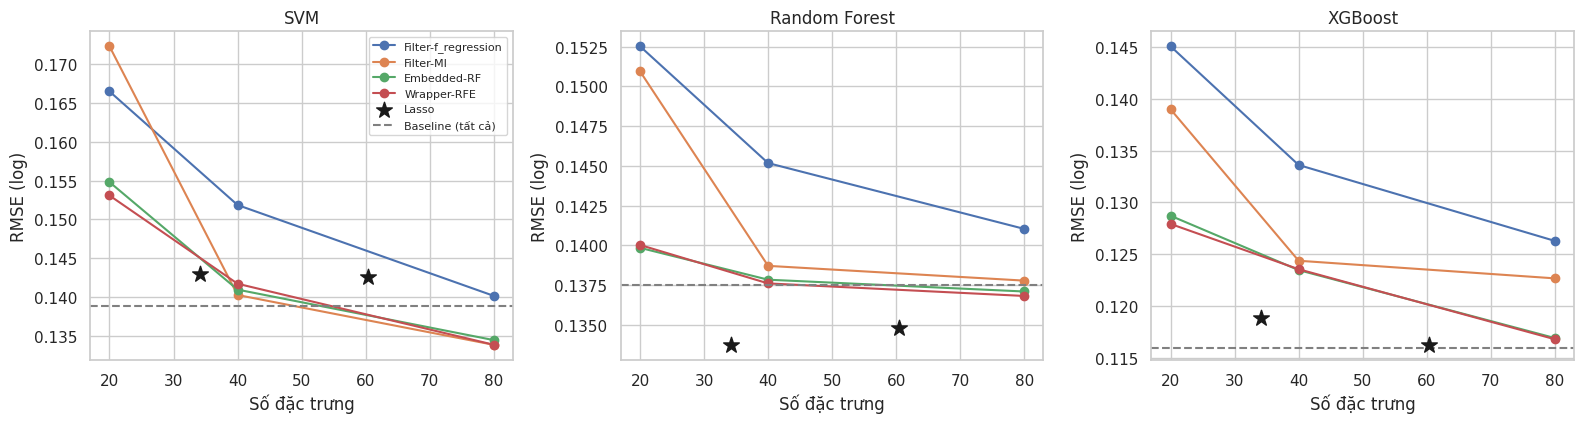

In [15]:
# RMSE theo số đặc trưng còn lại
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4), sharey=False)
families = ["Filter-f_regression", "Filter-MI", "Embedded-RF", "Wrapper-RFE"]
for ax, name in zip(axes, MODELS):
    sub = results[results["Model"] == name]
    for fam in families:
        s = sub[sub["Family"] == fam].sort_values("k")
        ax.plot(s["n_features"], s["RMSE"], marker="o", label=fam)
    lasso = sub[sub["Family"] == "Embedded-Lasso"]
    ax.scatter(lasso["n_features"], lasso["RMSE"], marker="*", s=140, color="k", label="Lasso", zorder=5)
    ax.axhline(sub.loc[sub["Family"] == "Baseline", "RMSE"].iloc[0], ls="--", color="gray", label="Baseline (tất cả)")
    ax.set(title=name, xlabel="Số đặc trưng", ylabel="RMSE (log)")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

### 2.2 Đặc trưng nào được chọn? (đối chiếu với EDA)

In [16]:
# Fit trên toàn bộ train chỉ để diễn giải (không dùng để đánh giá mô hình)
pre_full = build_preprocessor(scale=False)
Z_full = pre_full.fit_transform(X)
names = pre_full.get_feature_names_out()

rf = small_forest(300).fit(Z_full, y)
imp_rf = pd.Series(rf.feature_importances_, index=names).sort_values(ascending=False)
mi = pd.Series(mutual_info_regression(Z_full, y, random_state=RANDOM_STATE), index=names).sort_values(ascending=False)
lasso = lasso_selector(0.005).fit(Z_full, y)
coef = pd.Series(np.abs(lasso.estimator_.named_steps["lasso"].coef_), index=names).sort_values(ascending=False)

top = pd.DataFrame({"RF importance": imp_rf.index[:15], "Mutual Info": mi.index[:15], "Lasso |coef|": coef.index[:15]})
display(top)

ranks = pd.DataFrame({"RF": imp_rf.rank(ascending=False), "MI": mi.rank(ascending=False), "Lasso": coef.rank(ascending=False)})
key = ["OverallQual", "GrLivArea", "GarageCars", "TotalBsmtSF", "GarageArea", "TotRmsAbvGrd"]
print("Hạng (1 = quan trọng nhất) của các biến nêu trong EDA:")
display(ranks.loc[key].astype(int))

nb = [n for n in names if n.startswith("Neighborhood_")]
print("Neighborhood: hạng tốt nhất của một cột One-Hot — RF", int(ranks.loc[nb, "RF"].min()),
      "| MI", int(ranks.loc[nb, "MI"].min()), "| Lasso", int(ranks.loc[nb, "Lasso"].min()))

,RF importance,Mutual Info,Lasso |coef|
0,OverallQual,OverallQual,GrLivArea
1,GrLivArea,GrLivArea,OverallQual
2,TotalBsmtSF,GarageArea,YearBuilt
3,GarageCars,TotalBsmtSF,LotArea
4,GarageArea,YearBuilt,TotalBsmtSF
5,1stFlrSF,GarageCars,OverallCond
6,BsmtFinSF1,ExterQual,BsmtFinSF1
7,YearBuilt,KitchenQual,MSZoning_C (all)
8,LotArea,BsmtQual,GarageArea
9,CentralAir,1stFlrSF,Functional


Hạng (1 = quan trọng nhất) của các biến nêu trong EDA:


,RF,MI,Lasso
OverallQual,1,1,2
GrLivArea,2,2,1
GarageCars,4,6,11
TotalBsmtSF,3,4,5
GarageArea,5,3,9
TotRmsAbvGrd,26,17,162


Neighborhood: hạng tốt nhất của một cột One-Hot — RF 52 | MI 47 | Lasso 13


### 2.3 Kết luận

Kết quả (RMSE trên log1p(SalePrice), 5-fold CV; độ lệch chuẩn giữa các fold khoảng 0,008–0,013):

| Mô hình | Baseline | Tốt nhất khi dùng FS | Nhận xét |
|---|---|---|---|
| SVM | 0,1388 | 0,1339 (Mutual Info hoặc RFE-RF, k = 80) | cải thiện nhẹ (~3,5%) |
| Random Forest | 0,1375 | 0,1337 (Lasso, α = 0,01, 34 đặc trưng) | cải thiện nhẹ (~2,8%) |
| XGBoost | **0,1159** | 0,1159 (không chọn đặc trưng) | FS không cải thiện thêm |

**Nhận xét chính**
1. **XGBoost là mô hình tốt nhất** (RMSE 0,116, R² 0,915), tốt hơn rõ rệt SVM và Random Forest (RMSE khoảng 0,138); chênh lệch khoảng 0,022, gấp khoảng 2 lần độ lệch chuẩn giữa các fold.
2. **Chọn đặc trưng chủ yếu giúp giảm số cột (250 → 34–80) mà gần như giữ nguyên độ chính xác**, hơn là tăng độ chính xác. Các mức cải thiện của SVM và Random Forest (khoảng 0,004–0,005) nhỏ hơn một độ lệch chuẩn giữa các fold nên chưa đủ để khẳng định có ý nghĩa thống kê.
3. **Giữ quá ít đặc trưng làm xấu đi kết quả ở cả ba mô hình.** Với k = 20, RMSE tăng từ 0,002 đến 0,034 tùy kỹ thuật (tệ nhất là bộ lọc đơn biến trên SVM: 0,167 với `f_regression`, 0,172 với Mutual Info). Ở k = 80 (khoảng 1/3 số cột), RF importance và RFE-RF đã về mức baseline; các bộ lọc đơn biến vẫn kém hơn với XGBoost (0,123–0,126 so với 0,116).
4. **Bộ lọc đơn biến (`f_regression`, Mutual Info) kém hơn các phương pháp dựa trên mô hình khi k nhỏ.** Chúng chấm điểm từng cột độc lập nên bỏ sót tương tác và các cột One-Hot hiếm. RF importance và RFE-RF ổn định hơn (k = 20: RMSE 0,128–0,155; k = 40: sát baseline với SVM và Random Forest, XGBoost kém hơn khoảng 0,008).
5. **Lasso hợp với Random Forest nhưng không hợp với SVM.** Lasso (α = 0,01) giữ 34 đặc trưng, giúp Random Forest tốt hơn baseline nhưng làm SVM tệ hơn (0,143 so với 0,139) — tiêu chí tuyến tính không trùng với tiêu chí của kernel RBF.
6. **Loại `GarageArea`, `TotRmsAbvGrd` theo VIF không ảnh hưởng độ chính xác** (chênh dưới 0,0003), đúng với nhận định ở EDA rằng hai biến này dư thừa.
7. **Chi phí:** `f_regression` rẻ nhất; Mutual Info và RF importance thêm khoảng 1–2 giây mỗi fold với SVM và XGBoost; RFE-RF đắt nhất (khoảng 3,3–5,3 giây, gấp nhiều lần thời gian huấn luyện XGBoost hoặc SVM). Với tập dữ liệu nhỏ này, thời gian chọn đặc trưng lớn hơn thời gian tiết kiệm được khi huấn luyện.

**Đối chiếu với EDA (mục 2.2)**
- `OverallQual`, `GrLivArea`, `TotalBsmtSF` luôn nằm trong top 5 của cả RF importance và Mutual Info, `GarageCars` hạng 4–6 (Lasso: 11). Đây là các biến EDA dự đoán là quan trọng nhất.
- `TotRmsAbvGrd` xếp thấp (hạng 26 / 17 / 162), phù hợp quyết định loại bỏ. `GarageArea` vẫn xếp cao (hạng 3–9) dù tương quan mạnh với `GarageCars` (r = 0,88); hai biến thay thế được cho nhau nên loại một biến theo VIF không làm giảm độ chính xác (nhận xét 6).
- `Neighborhood` không xuất hiện trong top 15 của RF và Mutual Info vì thông tin bị chia nhỏ cho 25 cột One-Hot (cột tốt nhất chỉ hạng 52 và 47); Lasso xếp một cột `Neighborhood_Crawfor` ở hạng 13. Khi chọn theo từng cột dummy, các biến phân loại nhiều mức dễ bị đánh giá thấp. Có thể cải thiện bằng cách chọn theo biến gốc (gộp điểm của các cột dummy).

**Hạn chế**
- Chỉ dùng một lần chia 5-fold và một cấu hình siêu tham số cố định; chưa kiểm định so sánh cặp giữa các kỹ thuật.
- Số lượng đặc trưng k = 20, 40, 80 và α của Lasso là các giá trị chọn trước, chưa được tối ưu bằng CV lồng nhau.
